In [22]:
import scanpy as sc
import anndata as ad
import pandas as pd
import numpy as np
from pathlib import Path
import seaborn as sns
import seaborn.objects as so
import matplotlib.pyplot as plt

script_loc = Path('01_load_and_preprocess.py').resolve().parent
data_loc = script_loc.parent / "data"
resources_loc = script_loc.parent / 'resources'
outputs_loc = script_loc.parent / 'outputs_full'

In [ ]:
#Read in hm integrated datasets for each region
hcdata = sc.read_h5ad(data_loc / 'intermediate/hc_integrated.h5ad')
hpdata = sc.read_h5ad(data_loc / 'intermediate/hp_integrated.h5ad')

In [ ]:
#Find the number of cells clasified as microglia by either and both given and mapmycells annotation for caudate data
print(len(hcdata.obs[(hcdata.obs['celltype3'] == 'Microglia') | (hcdata.obs['supercluster_name'] == 'Microglia')]))
print(len(hcdata.obs[(hcdata.obs['celltype3'] == 'Microglia') & (hcdata.obs['supercluster_name'] == 'Microglia')]))

3385
3236


In [ ]:
#Find the number of cells clasified as microglia by either and both given and mapmycells annotation for putamen data
print(len(hpdata.obs[(hpdata.obs['celltype3'] == 'Microglia') | (hpdata.obs['supercluster_name'] == 'Microglia')]))
print(len(hpdata.obs[(hpdata.obs['celltype3'] == 'Microglia') & (hpdata.obs['supercluster_name'] == 'Microglia')]))

3251
3162


In [8]:
#Subest both caudate and putamen data to include only cells classified as microglia by either annotation method
mcdata = hcdata[(hcdata.obs['celltype3'] == 'Microglia') | (hcdata.obs['supercluster_name'] == 'Microglia')]
mpdata = hpdata[(hpdata.obs['celltype3'] == 'Microglia') | (hpdata.obs['supercluster_name'] == 'Microglia')]

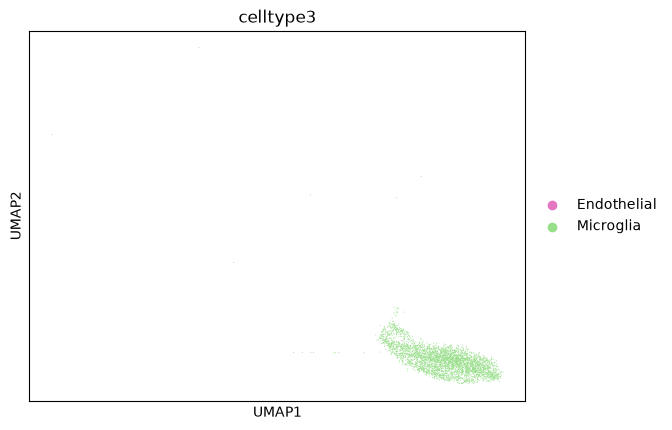

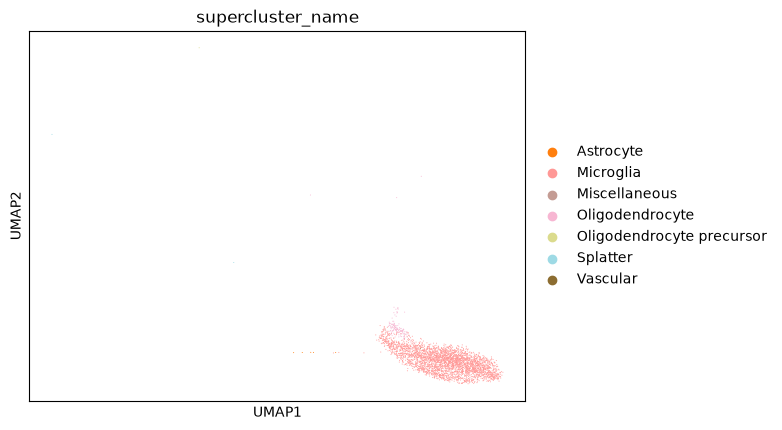

In [13]:
#Plot UMAP over new cell types and given cell types for spdata
sc.pl.umap(
    mcdata,
    color="celltype3",
    size=2,
    #save='_givencells_sp.png'
)
sc.pl.umap(
    mcdata,
    color="supercluster_name",
    size=2,
    #save='_mmcells_sp.png'
)

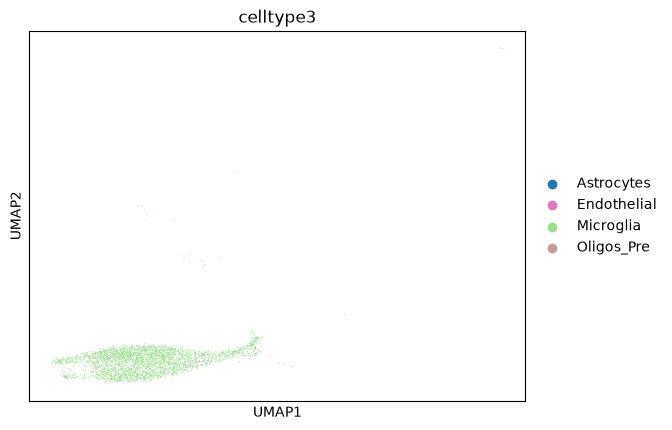

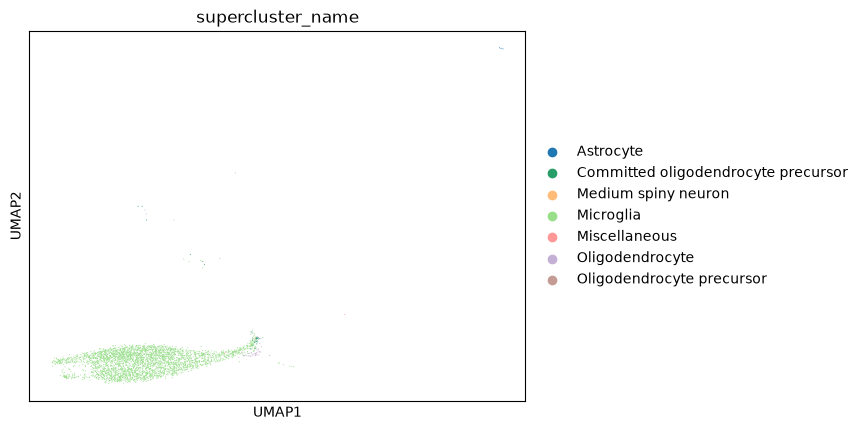

In [31]:
#Plot UMAP over new cell types and given cell types for spdata
sc.pl.umap(
    mpdata,
    color="celltype3",
    size=2,
    #save='_givencells_sp.png'
)
sc.pl.umap(
    mpdata,
    color="supercluster_name",
    size=2,
    #save='_mmcells_sp.png'
)

In [38]:
#Create a dataframe of every cells supercluster_name and celltype3 assignment for both regions
df_pcells = pd.DataFrame()
df_pcells['supercluster'] = mpdata.obs['supercluster_name']
df_pcells['celltype3'] = mpdata.obs['celltype3']

df_ccells = pd.DataFrame()
df_ccells['supercluster'] = mcdata.obs['supercluster_name']
df_ccells['celltype3'] = mcdata.obs['celltype3']

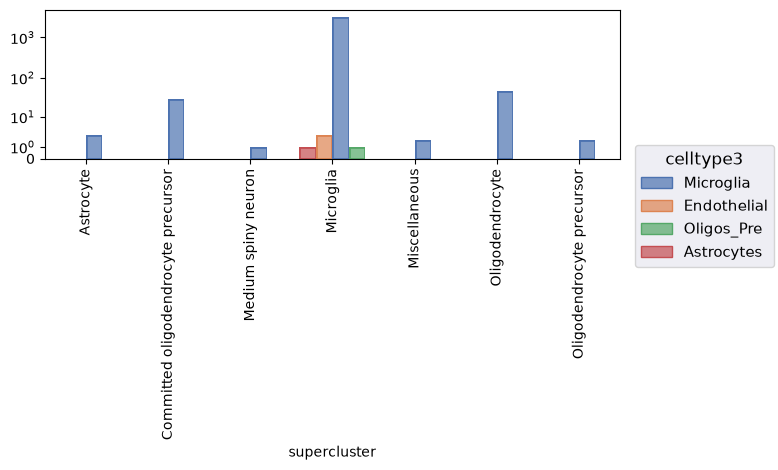

In [ ]:
fig, ax = plt.subplots()
(so.Plot(df_pcells, x='supercluster', color='celltype3')
    .add(so.Bar(), so.Hist(), so.Dodge())
    .scale(y='symlog')
    .on(ax)
    .layout(engine='tight')
    .plot()
)
ax.tick_params(axis="x", rotation=90)

plt.savefig(output_loc / 'exploration_figures/p_microglia_hist.png', dpi=300, bbox_inches='tight')
plt.show()

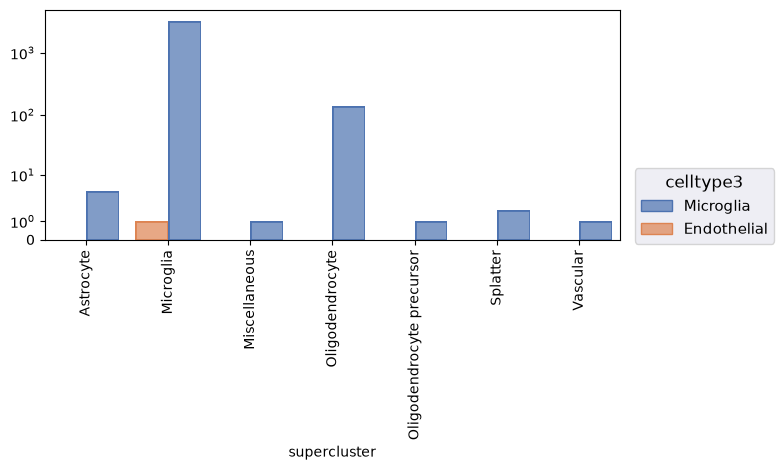

In [ ]:
fig, ax = plt.subplots()
(so.Plot(df_ccells, x='supercluster', color='celltype3')
    .add(so.Bar(), so.Hist(), so.Dodge())
    .scale(y='symlog')
    .on(ax)
    .layout(engine='tight')
    .plot()
)
ax.tick_params(axis="x", rotation=90)

plt.savefig(output_loc / 'exploration_figures/c_microglia_hist.png', dpi=300, bbox_inches='tight')
plt.show()

In [67]:
hmdata = ad.concat([mcdata, mpdata])

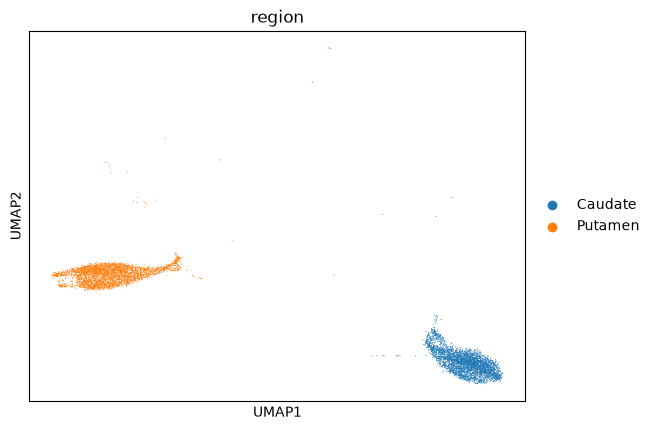

In [68]:
sc.pl.umap(
    hmdata,
    color="region",
    size=2,
    #save='_mmcells_sp.png'
)